# Convolutional Neural Networks (CNN) for Classification

Convolutional Neural Networks are built for data laid out on a grid, images above all. They learn local
patterns such as edges, corners and textures, and combine those into larger patterns that are useful for
classification.

This notebook builds one from the ground up. Every number in the network is derived rather than given:
you will work out by hand what a convolution does, why pooling shrinks an image, and where the mysterious
`64 * 7 * 7` in the code comes from. Then you train a CNN on two datasets, MNIST and CIFAR-10, and look
at what it actually learned.

## How to use this notebook

**What you should already know.** Notebook `01 Neural Network Foundations` (the training loop) and
notebook `02 PyTorch Foundations` (tensors, the image convention, `Dataset` and `DataLoader`,
`nn.Module`, the loop with validation). Basic Python and NumPy.

**Start with the warm-up** after the setup: the training loop from notebook `02` is given, you write
the model, and `assert` checks tell you when it is right.

**How to work through it.** Run every cell in order. Later cells use variables from earlier ones. Change
numbers and run a cell again; that is the fastest way to find out what a setting does.

**Time and patience.** Reading and the small experiments: about 2 hours. On top of that comes training,
measured on an ordinary laptop CPU:

| Step | Time | Note |
|---|---|---|
| Downloading MNIST | seconds | about 12 MB, once; notebook `02` may have done it already |
| Downloading CIFAR-10 | a minute or two | about 170 MB, once |
| Training on MNIST, 5 epochs | 2 to 5 minutes | |
| Training on CIFAR-10, 5 epochs | 5 to 15 minutes | |

So if a training cell runs for minutes, nothing is wrong. A GPU makes it faster but is not needed.

**What to expect.** After 5 epochs, MNIST lands around 99% test accuracy and CIFAR-10 around 70%. If your
numbers are in that neighbourhood, it worked. That gap between the two is itself one of the lessons.

**What you do _not_ need to master yet:** designing an architecture of your own, or squeezing out the best possible score.

## Learning objectives

After this notebook, you can:

- explain what one convolution filter computes, and work out a single output value by hand;
- predict the output size of a convolution or pooling layer from the input size, kernel size and padding,
  and therefore derive the `64 * 7 * 7` in the code instead of copying it;
- say what pooling is for, and what it throws away;
- read a small `nn.Module` and point out where the convolutions end and the classifier begins;
- train a CNN in PyTorch and read its learning curves;
- look at the filters a trained network learned and recognize what they respond to;
- explain why the same architecture does much better on MNIST than on CIFAR-10.

## 1. Setup

The two cells below import everything and download the data. A few notes before you run them:

- **PyTorch is required.** It is listed in this project's `pyproject.toml`, so `uv sync` installs it. If
  the import fails, your environment is not active. See notebook `01`.
- **The data is downloaded to `../data/raw`**, which is about 12 MB for MNIST and about 170 MB for
  CIFAR-10. This happens once; after that the files are reused. That directory is in `.gitignore`, so the
  datasets stay out of the repository.
- **If your network blocks the download** (a school proxy, for example), you will get a
  `URLError` or a 403. Download the datasets on another connection and copy the `../data/raw` folder
  across; `torchvision` then finds them and skips the download.

In [40]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

# Same idea as the random seed in notebook 01: make every run reproducible.
torch.manual_seed(42)

# A GPU is used automatically if there is one. Everything here also runs on a CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.1+cpu
Device: cpu


## Exercise: the model from notebook 02

Notebook `02` ended with a model as an `nn.Module` and the five-line training loop with a validation
pass. Before the convolutions start, build that model once more, from memory. The code below is almost
complete: MNIST is loaded, the loop is written, the checks are in place. Only the model is missing.

**The specification.** The class is called `SmallClassifier` and inherits from `nn.Module`. It has two
methods:

- `__init__(self, number_of_classes=10)`. It first calls `super().__init__()`, then stores
  `self.network`, an `nn.Sequential` of six layers:
  1. `nn.Flatten()`: an MNIST image is `1 x 28 x 28`, and a `Linear` layer wants one row of 784 numbers
     per image.
  2. `nn.Linear(28 * 28, 128)`: 784 inputs to 128 hidden units.
  3. `nn.ReLU()`: the activation in between.
  4. a second `nn.Linear` with 64 outputs. Its number of inputs is not given: work out what the layer
     before it hands over.
  5. `nn.ReLU()` again.
  6. a last `nn.Linear` with `number_of_classes` outputs, one per digit. Again, you work out the inputs.

  No softmax at the end. `nn.CrossEntropyLoss` applies it itself.
- `forward(self, images)`, which returns `self.network(images)`.

**How you know it is right.** The second cell ends in `assert` statements. When one fails you get a
message that says what to look at; when the cell prints "All checks passed", the class is correct. The
third cell then trains it, and its own check wants at least 85% of the validation digits right.

If Python complains about *cannot assign module before Module.__init__() call*, you forgot
`super().__init__()`. Keep the number this model reaches in mind: section 2 explains why a dense network
is the wrong tool for images, and section 7 trains the CNN that replaces it.


In [41]:
# MNIST as in notebook 02. Section 3 loads it again, properly, with a validation split.
mnist_train_full = datasets.MNIST(root="../data/raw", train=True, download=True,
                                  transform=transforms.ToTensor())
mnist_test_full = datasets.MNIST(root="../data/raw", train=False, download=True,
                                 transform=transforms.ToTensor())
print("training images:", len(mnist_train_full), "| test images:", len(mnist_test_full))


training images: 60000 | test images: 10000


In [42]:
class SmallClassifier(nn.Module):
    def __init__(self, number_of_classes=10):
        super().__init__()
        self.network = nn.Sequential(
            # TODO: the six layers, separated by commas
        )

    def forward(self, images):
        pass                                           # TODO: return the images after self.network


# ---- checks: do not change anything below this line ----
model = SmallClassifier()
test_batch = torch.rand(4, 1, 28, 28)                  # 4 fake images with the MNIST shape
output = model(test_batch)

assert output is not None, "forward() returned nothing: it should return self.network(images)"

assert tuple(output.shape) == (4, 10), (
    f"expected output shape (4, 10), got {tuple(output.shape)}: "
    "is nn.Flatten() the first layer, and does the last Linear produce 10 outputs? (a size mismatch between two Linear layers raises an error instead: read the two numbers in it)")
parameter_count = sum(p.numel() for p in model.parameters())

assert parameter_count == 109_386, (
    f"expected 109,386 trainable parameters, got {parameter_count:,}: "
    "each Linear takes as many inputs as the layer before it produces outputs")

assert not torch.allclose(output.sum(dim=1), torch.ones(4)), (
    "every output row sums to 1: remove the Softmax, CrossEntropyLoss applies it itself")

assert tuple(SmallClassifier(number_of_classes=2)(test_batch).shape) == (4, 2), (
    "number_of_classes is ignored: use it in the last Linear layer")

print(f"All checks passed: {parameter_count:,} parameters, output shape {tuple(output.shape)}. "
      "Now run the training cell.")


AssertionError: forward() returned nothing: it should return self.network(images)

In [43]:
train_data = Subset(mnist_train_full, range(4000))
validation_data = Subset(mnist_test_full, range(1000))

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
validation_loader = DataLoader(validation_data, batch_size=256, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

model = SmallClassifier().to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


def train_one_epoch(model, loader, dataset, loss_function, optimizer):
    model.train()                                       # training mode: dropout and batchnorm active
    running_loss = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()                           # 1. clear the old gradients
        predictions = model(images)                     # 2. forward pass
        loss = loss_function(predictions, labels)       # 3. how wrong are we
        loss.backward()                                 # 4. backpropagation
        optimizer.step()                                # 5. update the weights
        running_loss += loss.item() * len(labels)
    return running_loss / len(dataset)


def evaluate(model, loader, dataset, loss_function):
    model.eval()                                        # evaluation mode
    total_loss = correct = 0
    with torch.no_grad():                               # no gradients needed
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            predictions = model(images)
            total_loss += loss_function(predictions, labels).item() * len(labels)
            correct += (predictions.argmax(dim=1) == labels).sum().item()
    return total_loss / len(dataset), correct / len(dataset)


for epoch in range(10):
    train_loss = train_one_epoch(model, train_loader, train_data, loss_function, optimizer)
    validation_loss, validation_accuracy = evaluate(model, validation_loader, validation_data, loss_function)
    print(f"epoch {epoch + 1}: train loss {train_loss:.4f} | "
          f"validation loss {validation_loss:.4f} | accuracy {validation_accuracy:.4f}")

# ---- check ----
assert validation_accuracy > 0.85, (
    f"accuracy {validation_accuracy:.3f} is too low for this model: compare your layers with the specification")
print(f"\nCheck passed: {validation_accuracy:.1%} of the validation digits correct.")


device: cpu


ValueError: optimizer got an empty parameter list

<details>
<summary>Solution</summary>

```python
class SmallClassifier(nn.Module):
    def __init__(self, number_of_classes=10):
        super().__init__()                             # never forget this line
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),              # inputs: what the layer before produces
            nn.ReLU(),
            nn.Linear(64, number_of_classes),
        )

    def forward(self, images):
        return self.network(images)
```

The two missing input sizes follow from the chain: the first `Linear` produces 128 numbers per image, so
the second takes 128; it produces 64, so the last takes 64. Get one wrong and PyTorch raises an error
with both numbers in it ("mat1 and mat2 shapes cannot be multiplied"), which is the fastest way to find
the mistake.

Where the 109,386 parameters come from: `784 * 128 + 128` = 100,480 in the first `Linear`,
`128 * 64 + 64` = 8,256 in the second, `64 * 10 + 10` = 650 in the last. `Flatten` and `ReLU` have none.

Two versions that pass the checks but are still wrong: an extra `nn.ReLU()` after the last `Linear`
(the network can then never output a negative score, and training is noticeably worse), and `Flatten`
placed after the first `Linear` (that one fails the shape check, which is the point of the check).

Ten epochs give about 91% on the 1,000 validation digits. The CNN in section 7 gets to 99% on the full
test set, and section 2 explains why.

</details>


## 2. Why a CNN and not a dense network

In earlier exercises every input was a separate feature with its own weight. You can do that with an image:
flatten 28 by 28 pixels into 784 numbers and feed them to a dense layer. You just did, in the warm-up,
and it works. But it wastes almost everything an image has to offer.

Two problems. First, **position**. A dense layer learns a separate weight for every pixel position, so a
pattern it has learned in the top-left corner means nothing to it in the bottom-right corner. It would
have to learn the same thing again, in every position. Second, **cost**. Count the parameters:

| | Parameters | What it can find |
|---|---|---|
| Dense layer, 784 inputs to 32 units | `784 * 32 + 32` = **25,120** | 32 patterns, each tied to one fixed position |
| Convolution layer, 32 filters of 3 by 3 | `32 * (1 * 3 * 3 + 1)` = **320** | 32 patterns, anywhere in the image |

Where do those numbers come from? Every unit has two kinds of parameters:

- **One weight per input.** A unit in the dense layer looks at all 784 pixels, and each pixel gets its own
  weight. With 32 units that is `784 * 32` = 25,088 weights.
- **One bias per unit.** The bias is one extra number that is added to the weighted sum, whatever the
  pixels are. It decides how easily the unit switches on, like the starting score of a vote before any
  pixel has voted. It does not belong to a pixel, it belongs to the unit, so 32 units have 32 biases.

Together that is `784 * 32 + 32` = 25,088 + 32 = **25,120**. As a rule for any dense layer: inputs times
units, plus one bias per unit.

The convolution row follows the same rule, with the sizes of a filter instead. One filter looks at a
3 by 3 patch of 1 channel, so it has `1 * 3 * 3` = 9 weights and 1 bias, which is the `(1 * 3 * 3 + 1)`.
That is 10 parameters per filter, and 32 filters give `32 * 10` = **320**. The filter does not have a
weight per image position, only per position in the patch, and that is why the number is so small.

Eighty times fewer parameters, and the result is more useful. That is the trade a convolution makes: it
gives up "every pixel gets its own weight" in exchange for "one small pattern, applied everywhere".

Four terms you will meet for this idea:

- **local receptive field**: each output value looks at a small patch of the input, not the whole image;
- **shared weights**: the same small filter slides across the entire image;
- **translation invariance**: a pattern is recognized wherever it appears;
- **hierarchical features**: early layers find edges, later layers combine those into shapes and parts.

The rest of this notebook makes each of these concrete rather than leaving them as bullet points.

**Key terms.** *Filter* (or *kernel*): the small grid of weights that slides over the image.
*Feature map*: the output of one filter over the whole image. *Channel*: one layer of a multi-layer
image; a grayscale image has 1, a colour image has 3.

## 3. The data in PyTorch

Everything in the next cell is notebook `02`: `ToTensor()` turns each image into a `(1, 28, 28)` tensor
with values between 0 and 1, `random_split` carves a validation set out of the training data, and the
`DataLoader` hands out shuffled batches of shape `(128, 1, 28, 28)`, that is `(batch, channels, height,
width)`. If any of that looks new, go back to notebook `02`, sections 2 and 3, first.

In [44]:
mnist_transform = transforms.ToTensor()

mnist_full = datasets.MNIST(
    root="../data/raw", train=True, download=True, transform=mnist_transform
)
mnist_test = datasets.MNIST(
    root="../data/raw", train=False, download=True, transform=mnist_transform
)

# Three sets, as in notebook 01: train to fit, validation to choose, test to report once.
mnist_train, mnist_validation = random_split(
    mnist_full, [54000, 6000], generator=torch.Generator().manual_seed(42)
)

mnist_train_loader = DataLoader(mnist_train, batch_size=128, shuffle=True)
mnist_validation_loader = DataLoader(mnist_validation, batch_size=128)
mnist_test_loader = DataLoader(mnist_test, batch_size=128)

first_image, first_label = mnist_full[0]
print("one sample :", tuple(first_image.shape), "-> (channels, height, width), label", first_label)
print("pixel range:", float(first_image.min()), "to", float(first_image.max()))

batch_images, batch_labels = next(iter(mnist_train_loader))
print("one batch  :", tuple(batch_images.shape), "-> (batch, channels, height, width)")
print("train / validation / test:", len(mnist_train), "/", len(mnist_validation), "/", len(mnist_test))


one sample : (1, 28, 28) -> (channels, height, width), label 5
pixel range: 0.0 to 1.0
one batch  : (128, 1, 28, 28) -> (batch, channels, height, width)
train / validation / test: 54000 / 6000 / 10000


Before training anything, look at it. This is a habit worth keeping: half of all modelling problems are
visible in the raw data.

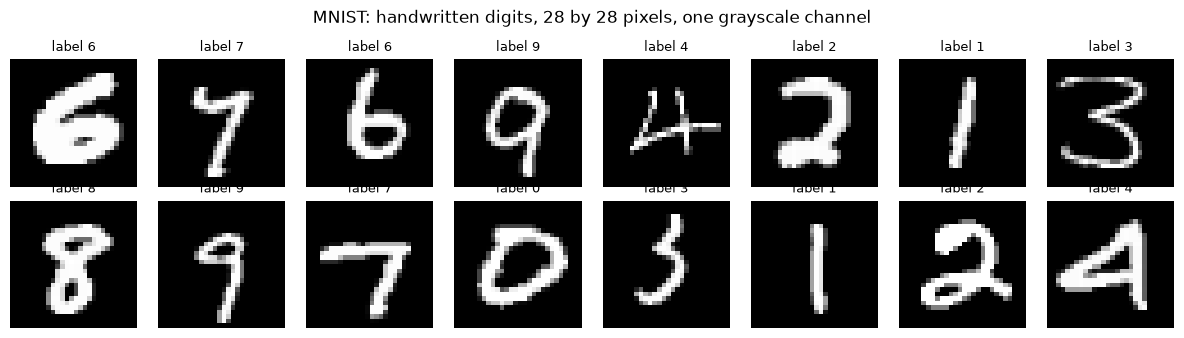

In [45]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, index in zip(axes.ravel(), range(16)):
    image, label = mnist_train[index]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"label {label}", fontsize=9)
    ax.axis("off")
fig.suptitle("MNIST: handwritten digits, 28 by 28 pixels, one grayscale channel")
plt.tight_layout()
plt.show()

Black background, white strokes, every digit roughly centred and roughly the same size. That uniformity is
why MNIST is easy, and it is exactly what CIFAR-10 will not give you in section 9.

Note `image.squeeze()` in the code: the tensor is `(1, 28, 28)` and Matplotlib wants `(28, 28)`, so the
channel dimension of size 1 is squeezed out.

## 4. Convolution, worked out by hand

A convolution slides a small grid of weights (the **filter**) over the image. At every position it
multiplies the overlapping numbers pairwise and adds them up. One number out per position. That is all.

Start with a 5 by 5 image containing a white square, and this filter:

```text
 1  0  -1
 1  0  -1
 1  0  -1
```

The left column counts positively, the right column negatively, and the middle is ignored. So the filter
computes "how much brighter is the left side than the right side?". In a flat area the answer is 0; at an
edge from light to dark it is strongly positive; at an edge from dark to light, strongly negative. This is
a **vertical edge detector**, and you can read that off the numbers rather than being told.

In [ ]:
image_patch = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 1, 1, 1, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0],
], dtype=float)

vertical_edge = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1],
], dtype=float)

print("image:\n", image_patch)
print("\nfilter:\n", vertical_edge)

# One single position, step by step: the top-left 3x3 window.
window = image_patch[0:3, 0:3]
print("\nwindow at position (0, 0):\n", window)
print("\nwindow * filter, element by element:\n", window * vertical_edge)
print("\nsum of those nine numbers:", (window * vertical_edge).sum())

image:
 [[0. 0. 0. 0. 0.]
 [0. 1. 1. 1. 0.]
 [0. 1. 1. 1. 0.]
 [0. 1. 1. 1. 0.]
 [0. 0. 0. 0. 0.]]

filter:
 [[ 1.  0. -1.]
 [ 1.  0. -1.]
 [ 1.  0. -1.]]

window at position (0, 0):
 [[0. 0. 0.]
 [0. 1. 1.]
 [0. 1. 1.]]

window * filter, element by element:
 [[ 0.  0. -0.]
 [ 0.  0. -1.]
 [ 0.  0. -1.]]

sum of those nine numbers: -2.0


That single number is one pixel of the output. The window sees the left edge of the white square: a dark
column on the left, bright on the right, so the sum comes out negative.

Now repeat for every position the window fits.

In [46]:
feature_map = np.zeros((3, 3))
for row in range(3):
    for column in range(3):
        window = image_patch[row:row + 3, column:column + 3]
        feature_map[row, column] = (window * vertical_edge).sum()

print("feature map:\n", feature_map)

feature map:
 [[-2.  0.  2.]
 [-3.  0.  3.]
 [-2.  0.  2.]]


Read the result: the left column is `-3` (the left edge of the square), the right column is `+3` (the
right edge), and the middle column is `0` (inside the square nothing changes from left to right). The
filter found both vertical edges and ignored the flat interior. Exactly what its numbers promised.

### The same thing on a real image

Four filters over one MNIST digit. `F.conv2d` is the same operation you just wrote by hand, and the
network uses it too. The only difference is that the network *learns* the filter values instead of you
picking them.

In [47]:
# a single digit, shape (1, 28, 28), the 8th image in the training set, which is a 3
digit_image, digit_label = mnist_full[7]        

# Four 3 by 3 filters, each one a variable of its own.
vertical_edges = [[1, 0, -1],
                  [1, 0, -1],
                  [1, 0, -1]]

horizontal_edges = [[1, 1, 1],
                    [0, 0, 0],
                    [-1, -1, -1]]

blur = [[1 / 9, 1 / 9, 1 / 9],            # the local average
        [1 / 9, 1 / 9, 1 / 9],
        [1 / 9, 1 / 9, 1 / 9]]

sharpen = [[0, -1, 0],
           [-1, 5, -1],
           [0, -1, 0]]

# Stack them into one tensor: (4 filters, 3, 3), then add the channel dimension.
hand_made_filters = torch.tensor([vertical_edges, horizontal_edges, blur, sharpen],
                                 dtype=torch.float32).unsqueeze(1)   # -> (4 filters, 1 channel, 3, 3)

# F.conv2d is a convolution layer without the learning: it slides every filter over the image,
# exactly as you did by hand above, and returns one output image (feature map) per filter.
# It is a simulation of a Conv2d layer whose 4 filters are the ones we chose ourselves, where a
# real layer would start with random filters and learn them. All 4 filters go through in one call.
#
# What goes in:
#   digit_image.unsqueeze(0): the image as a batch of 1, (1, 28, 28) -> (1, 1, 28, 28)
#   hand_made_filters:        the 4 filters, shape (4 filters, 1 channel, 3, 3)
#   padding=1:                a border of zeros, so the output stays 28 by 28
# What comes out: (1, 4, 28, 28), 4 feature maps for the one image. The [0] removes the batch
# dimension again, which leaves (4, 28, 28).
filtered = F.conv2d(digit_image.unsqueeze(0), hand_made_filters, padding=1)[0]

# What is filtered? A stack of 4 images (feature maps), one per filter, in the order we stacked them.
print("filtered       :", tuple(filtered.shape), "-> (4 filters, 28 high, 28 wide)")
print("filtered[0]    :", tuple(filtered[0].shape), "-> the vertical-edges image, 28 by 28 pixels")
print("filtered[1]    :", tuple(filtered[1].shape), "-> the horizontal-edges image")
print("filtered[2]    :", tuple(filtered[2].shape), "-> the blurred image")
print("filtered[3]    :", tuple(filtered[3].shape), "-> the sharpened image")
print("filtered[0, 5, 5]:", round(float(filtered[0, 5, 5]), 3),
      "-> one pixel of the vertical-edges image, the filter applied at row 5, column 5")

# The values are no longer between 0 and 1: edge filters give positive numbers on one kind of edge,
# negative on the other, and about 0 on flat areas.
for index, label in enumerate(["vertical edges", "horizontal edges", "blur", "sharpen"]):
    feature_map = filtered[index]
    print(f"{label:<17} min {float(feature_map.min()):6.2f}  max {float(feature_map.max()):5.2f}")


filtered       : (4, 28, 28) -> (4 filters, 28 high, 28 wide)
filtered[0]    : (28, 28) -> the vertical-edges image, 28 by 28 pixels
filtered[1]    : (28, 28) -> the horizontal-edges image
filtered[2]    : (28, 28) -> the blurred image
filtered[3]    : (28, 28) -> the sharpened image
filtered[0, 5, 5]: 0.0 -> one pixel of the vertical-edges image, the filter applied at row 5, column 5
vertical edges    min  -2.79  max  2.97
horizontal edges  min  -2.98  max  2.98
blur              min   0.00  max  0.99
sharpen           min  -1.69  max  2.83


Plot the original and filtered images:

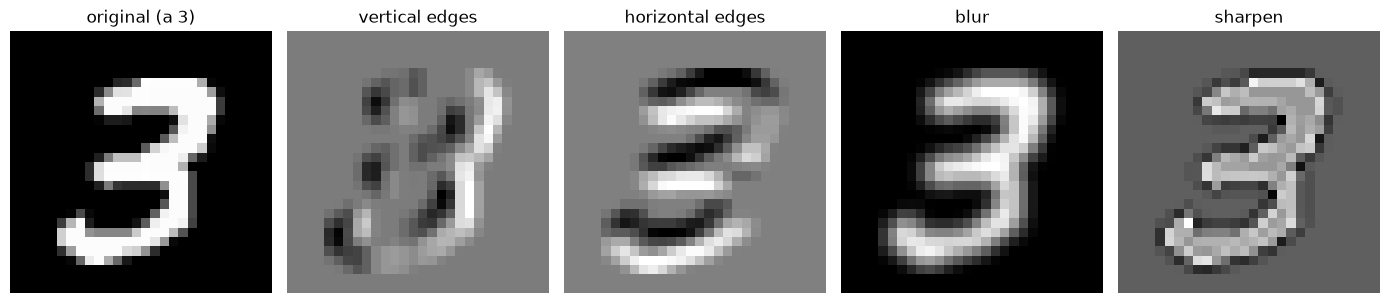

In [48]:
# Plot the original and the 4 filtered images next to each other: 1 row, 5 panels.
names = ["vertical edges", "horizontal edges", "blur", "sharpen"]    # same order as the filters
fig, axes = plt.subplots(1, 5, figsize=(14, 3))      # axes is a list of 5 panels

# Panel 0: the original digit. squeeze() removes the channel dimension, (1, 28, 28) -> (28, 28),
# because imshow wants a plain 2D image.
axes[0].imshow(digit_image.squeeze(), cmap="gray")
axes[0].set_title(f"original (a {digit_label})")

# Panels 1 to 4: one filtered image each. Looping over `filtered` hands out filtered[0], filtered[1],
# and so on, each a (28, 28) image. zip pairs every image with its panel and its name.
for ax, feature, name in zip(axes[1:], filtered, names):
    ax.imshow(feature, cmap="gray")
    ax.set_title(name)

# No axis ticks or numbers: they are pixel positions and only distract here.
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

The vertical-edge filter lights up on the left and right sides of the strokes and stays grey where the
stroke runs horizontally; the horizontal filter does the opposite. Blur and sharpen are the same
operation with different numbers. Nothing about this is specific to neural networks: these are the
classic image filters from any photo editor. What a CNN adds is that it *searches* for the filter values
that make the classification work, instead of you choosing them.

**Key terms.** *Kernel size*: how large the window is. *Padding*: a border of zeros so the output keeps
its size. *Stride*: how far the window jumps each step (1 here, the default). *Feature map*: the output
of one filter.

**Do it yourself**

1. Build a filter that responds to a diagonal edge and try it on the digit.
2. What does a filter of all zeros produce? And one with a single `1` in the middle?
3. Apply the blur filter twice in a row to the digit. What happens, and what does that tell you about stacking layers?

**Going further** (optional). Use a 5 by 5 filter on `image_patch` instead of 3 by 3. Predict the output size with the formula before you run it, then check.

In [ ]:
# Your turn.
# diagonal_edge = 


## 5. Pooling: making the image smaller

After a convolution you usually know *where* something was found in more detail than you need. Pooling
throws that excess detail away. `MaxPool2d(2)` divides the image into 2 by 2 blocks and keeps only the
largest value in each block.

In [49]:
small_image = torch.tensor([[[
    [1.0, 3.0, 2.0, 4.0],
    [5.0, 6.0, 1.0, 2.0],
    [7.0, 2.0, 3.0, 1.0],
    [0.0, 4.0, 8.0, 9.0],
]]])                                  # shape (1, 1, 4, 4)

pooled = nn.MaxPool2d(2)(small_image)

print("before pooling (4 by 4):\n", small_image[0, 0].numpy())
print("\nafter MaxPool2d(2) (2 by 2):\n", pooled[0, 0].numpy())
print("\ntop-left block is", small_image[0, 0, :2, :2].numpy().tolist(), "-> largest is", float(pooled[0, 0, 0, 0]))

before pooling (4 by 4):
 [[1. 3. 2. 4.]
 [5. 6. 1. 2.]
 [7. 2. 3. 1.]
 [0. 4. 8. 9.]]

after MaxPool2d(2) (2 by 2):
 [[6. 4.]
 [7. 9.]]

top-left block is [[1.0, 3.0], [5.0, 6.0]] -> largest is 6.0


Four numbers become one, so height and width are halved and three quarters of the values are discarded.
What survives is "the strongest response in this neighbourhood", which is usually what matters: that an
edge was found somewhere in this corner is useful, its exact pixel is not.

Two consequences worth remembering. Pooling makes the network **cheaper** (fewer values to process) and
slightly **shift-tolerant** (move the digit one pixel and the pooled output often stays the same). The
price is resolution, and you cannot get it back.

Watch what two pooling steps do to a real digit.

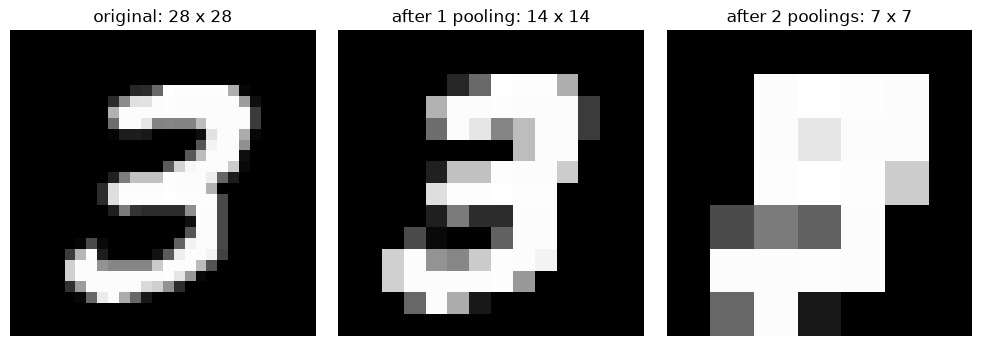

In [ ]:
pool = nn.MaxPool2d(2)
once = pool(digit_image.unsqueeze(0))
twice = pool(once)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, picture, title in zip(
    axes,
    [digit_image.squeeze(), once[0, 0], twice[0, 0]],
    ["original: 28 x 28", "after 1 pooling: 14 x 14", "after 2 poolings: 7 x 7"],
):
    ax.imshow(picture, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

At 14 by 14 it is still clearly a 3. At 7 by 7 it is mostly a white blob. You would be guessing. That is
the real lesson of this picture: pooling is useful, but every step costs information you cannot get back,
and a few steps in there is nothing left to classify. It is also why this network pools exactly twice and
then stops.

(Notice too that the strokes get *fatter*. Max pooling keeps the brightest value in each block, so a
single bright pixel spreads over its neighbourhood.)

And note the last number: **7 by 7**. Keep it in mind for the next section.

**Key terms.** *Pooling*: reducing resolution by summarizing small blocks. *Max pooling*: keep the
largest value. *Receptive field*: how much of the original image one value has seen.

## 6. First CNN

The layers:

- `Conv2d(..., kernel_size=3, padding=1)` leaves height and width **unchanged**, and sets the number of
  channels to the number of filters;
- `MaxPool2d(2)` **halves** height and width, and leaves the channels alone.

Walk the MNIST network through:

| Step | Shape (channels, height, width) | Why |
|---|---|---|
| input | `1 x 28 x 28` | one grayscale channel |
| `Conv2d(1, 32, 3, padding=1)` | `32 x 28 x 28` | 32 filters, size unchanged |
| `ReLU` | `32 x 28 x 28` | activations never change shape |
| `MaxPool2d(2)` | `32 x 14 x 14` | halved |
| `Conv2d(32, 64, 3, padding=1)` | `64 x 14 x 14` | 64 filters, size unchanged |
| `ReLU` | `64 x 14 x 14` | |
| `MaxPool2d(2)` | `64 x 7 x 7` | halved again |
| `Flatten` | `3136` | 64 × 7 × 7 = 3136 numbers in a row |

So `64 * 7 * 7` is simply "what comes out of the convolution part". Change one layer and this number
changes with it, which is why a shape error is the first thing you get when you edit a CNN.

You never have to do this on paper. Send one batch through and print the shape after every layer.

In [50]:
demo_features = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
)

x = torch.randn(1, 1, 28, 28)                 # one fake image, right shape
print(f"{'input':34} {tuple(x.shape)}")
for layer in demo_features:
    x = layer(x)
    print(f"{str(layer):34} {tuple(x.shape)}")
print(f"\nflattened: {x.numel()} numbers  ->  nn.Linear({x.numel()}, 128)")

input                              (1, 1, 28, 28)
Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)) (1, 32, 28, 28)
ReLU()                             (1, 32, 28, 28)
MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False) (1, 32, 14, 14)
Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)) (1, 64, 14, 14)
ReLU()                             (1, 64, 14, 14)
MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False) (1, 64, 7, 7)

flattened: 3136 numbers  ->  nn.Linear(3136, 128)


Three lines of code and the mystery is gone. Keep this trick: when you change a CNN and PyTorch complains
about shapes, print the shapes and the error explains itself.

## 7. The model and the training loop

You now have all the pieces of a CNN, and the PyTorch side you already know from notebook `02`: a model
is an `nn.Module` with `__init__` and `forward`, the loss is `nn.CrossEntropyLoss()` on raw scores
(*logits*, so no softmax at the end of the network), the optimizer is Adam, and the loop is the same five
lines with `model.train()` before training, `model.eval()` and `torch.no_grad()` around evaluation.

Two things are specific to a CNN:

- **The network is split in two.** A `features` part (convolutions and pooling, with the shapes from
  section 6) finds patterns; a `classifier` part (flatten, then dense layers) turns those patterns into
  ten class scores. PyTorch does not require the split, but it mirrors how a CNN thinks, and it lets you
  inspect the two halves separately.
- **`nn.Flatten()` is the bridge.** It lays the `64 x 7 x 7` feature maps out as one row of 3136 numbers,
  which is what a dense layer expects. The `64 * 7 * 7` in the code is that same number, and you derived
  it in section 6.

**Key terms.** *Logits*: raw scores before softmax. *Flatten*: laying all feature maps out in a single
row of numbers. *Features / classifier*: the pattern-finding half and the deciding half of a CNN.

In [ ]:
class MNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # The convolution part: find patterns. Shapes are the table from section 6.
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),   # 1 x 28 x 28 -> 32 x 28 x 28
            nn.ReLU(),
            nn.MaxPool2d(2),                              #            -> 32 x 14 x 14
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  #            -> 64 x 14 x 14
            nn.ReLU(),
            nn.MaxPool2d(2),                              #            -> 64 x  7 x  7
        )
        # The classifier: turn those patterns into 10 class scores.
        self.classifier = nn.Sequential(
            nn.Flatten(),                                 #            -> 3136
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),                              # regularization: part of following notebooks
            nn.Linear(128, 10),                           # 10 logits, one per digit
        )

    def forward(self, images):
        return self.classifier(self.features(images))


model_mnist = MNISTCNN().to(device)
print(model_mnist)

MNISTCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


Note the split into `features` and `classifier`. That is not required by PyTorch, but it mirrors how a CNN
thinks: first find patterns, then decide. It also lets you inspect the two halves separately, which is
exactly what the next cell does.

In [52]:
def count_parameters(module):
    return sum(parameter.numel() for parameter in module.parameters())

convolution_parameters = count_parameters(model_mnist.features)
dense_parameters = count_parameters(model_mnist.classifier)
total = convolution_parameters + dense_parameters

print(f"convolution part : {convolution_parameters:>9,}")
print(f"classifier part  : {dense_parameters:>9,}")
print(f"total            : {total:>9,}")
print(f"\nshare of the parameters in the dense head: {dense_parameters / total:.0%}")

convolution part :    18,816
classifier part  :   402,826
total            :   421,642

share of the parameters in the dense head: 96%


That number is worth a pause. All the convolutions together (the part that does the actual image work)
hold under 5% of the parameters. The overwhelming majority sits in the single `Linear(3136, 128)` layer
right after the flatten.

This is the same counting rule as in notebook 01 (one weight per connection plus one bias per unit),
and it corrects a common intuition:
convolutions are *cheap* precisely because they share weights. Flattening into a large dense layer is
expensive. It also tells you where to look first if a network is too big, and it is the reason the
adaptive pooling trick from exercise 2C exists.

In [53]:
def train_one_epoch(model, loader, dataset, loss_function, optimizer):
    """One pass over the training data. Returns the average loss and accuracy."""
    model.train()                                     # dropout on
    total_loss = correct = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        predictions = model(images)
        loss = loss_function(predictions, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        correct += (predictions.argmax(dim=1) == labels).sum().item()
    return total_loss / len(dataset), correct / len(dataset)


def evaluate(model, loader, dataset, loss_function):
    """The same walk over the data, but without learning anything."""
    model.eval()                                      # dropout off
    total_loss = correct = 0
    with torch.no_grad():                             # no gradients needed
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            predictions = model(images)
            total_loss += loss_function(predictions, labels).item() * len(labels)
            correct += (predictions.argmax(dim=1) == labels).sum().item()
    return total_loss / len(dataset), correct / len(dataset)

The cell below does the actual training. **This takes a few minutes**; the per-epoch output tells you it
is alive. Each epoch it trains on 54,000 images and then checks 6,000 validation images it did not train
on.

In [54]:
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_mnist.parameters(), lr=1e-3)
history_mnist = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}

epochs = 5
for epoch in range(epochs):
    train_loss, train_accuracy = train_one_epoch(
        model_mnist, mnist_train_loader, mnist_train, loss_function, optimizer
    )
    validation_loss, validation_accuracy = evaluate(
        model_mnist, mnist_validation_loader, mnist_validation, loss_function
    )
    history_mnist["loss"].append(train_loss)
    history_mnist["val_loss"].append(validation_loss)
    history_mnist["accuracy"].append(train_accuracy)
    history_mnist["val_accuracy"].append(validation_accuracy)
    print(
        f"epoch {epoch + 1}: "
        f"train accuracy={train_accuracy:.4f}  validation accuracy={validation_accuracy:.4f}"
    )


epoch 1: train accuracy=0.9122  validation accuracy=0.9780
epoch 2: train accuracy=0.9753  validation accuracy=0.9815
epoch 3: train accuracy=0.9821  validation accuracy=0.9857
epoch 4: train accuracy=0.9856  validation accuracy=0.9867
epoch 5: train accuracy=0.9871  validation accuracy=0.9893


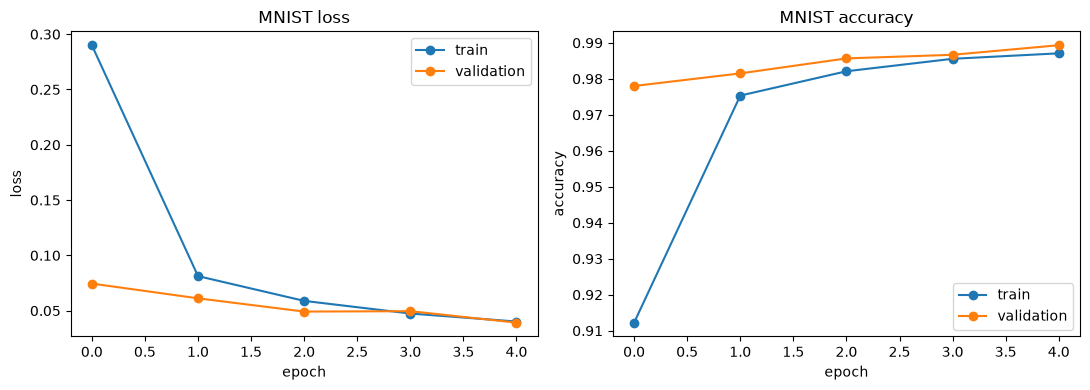

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_mnist["loss"], marker="o", label="train")
axes[0].plot(history_mnist["val_loss"], marker="o", label="validation")
axes[0].set(xlabel="epoch", ylabel="loss", title="MNIST loss")
axes[0].legend()
axes[1].plot(history_mnist["accuracy"], marker="o", label="train")
axes[1].plot(history_mnist["val_accuracy"], marker="o", label="validation")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="MNIST accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

Read these curves as a pair, training against validation. But first, something that surprises everyone here: the
**validation line sits above the training line**. Shouldn't a model do better on the data it trained on?

Two reasons, both harmless:

1. The training accuracy is the *average over the whole epoch*, measured while the model was still
   improving. The validation accuracy is measured afterwards, with the finished model. So you are
   comparing an average with an end result.
2. Dropout is active during training and switched off during evaluation. The training numbers therefore
   come from a deliberately handicapped network.

The gap closes as the epochs go by, exactly as those two explanations predict. What you are looking for
is the opposite pattern: training accuracy climbing while validation flattens or falls. That is
overfitting, and section 9 will show it to you on CIFAR-10.

## 8. What did the network learn?

In the previous sections you chose the filters yourself. Training chooses them by gradient descent instead. So what
did it come up with? The first convolution layer has 32 filters of 3 by 3, and you can simply look at
them.

filters of the first layer: (32, 1, 3, 3) -> 32 filters of 1 x 3 x 3


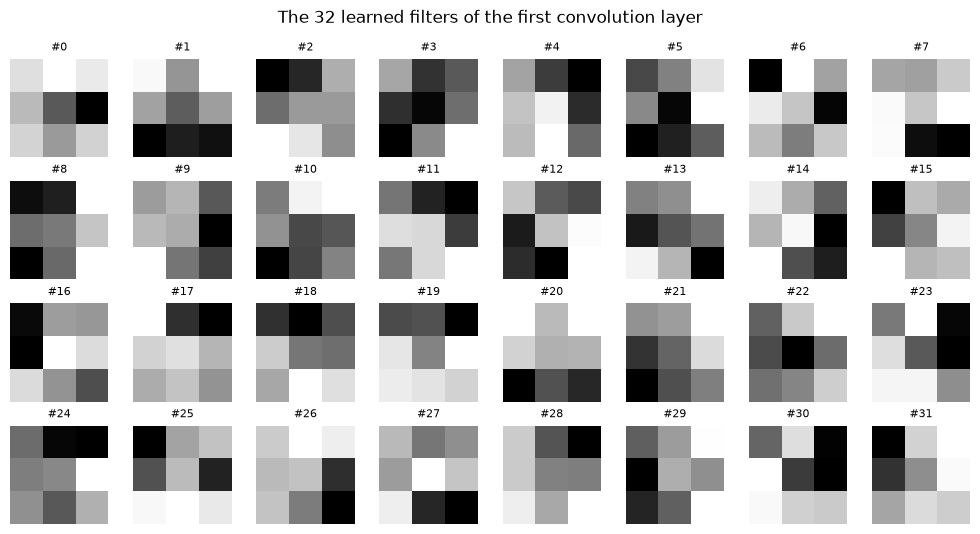

In [56]:
first_layer_filters = model_mnist.features[0].weight.detach().cpu()
print("filters of the first layer:", tuple(first_layer_filters.shape), "-> 32 filters of 1 x 3 x 3")

fig, axes = plt.subplots(4, 8, figsize=(10, 5.4))
for index, ax in enumerate(axes.ravel()):
    ax.imshow(first_layer_filters[index, 0], cmap="gray")
    ax.set_title(f"#{index}", fontsize=8)
    ax.axis("off")
fig.suptitle("The 32 learned filters of the first convolution layer")
plt.tight_layout()
plt.show()

Look for the pattern: many of these filters have a light side and a dark side, split horizontally,
vertically or diagonally: the same shape as the edge detectors you built by hand in section 4. Others
look scattered and hard to interpret, which is normal; not every filter ends up doing something tidy, and
some barely contribute at all.

The point is that nobody designed these. They are what came out of the gradient, and the network arrived
at edge detectors on its own because edges are what makes a digit a digit.

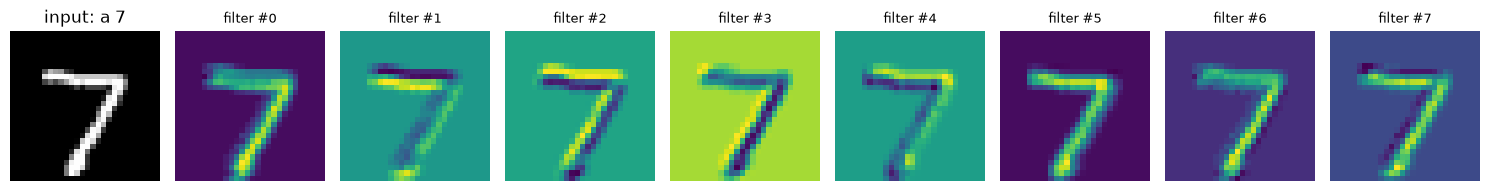

In [57]:
test_digit, test_label = mnist_test[0]
with torch.no_grad():
    responses = model_mnist.features[0](test_digit.unsqueeze(0).to(device))[0].cpu()

fig, axes = plt.subplots(1, 9, figsize=(15, 2.4))
axes[0].imshow(test_digit.squeeze(), cmap="gray")
axes[0].set_title(f"input: a {test_label}")
for index in range(8):
    axes[index + 1].imshow(responses[index], cmap="viridis")
    axes[index + 1].set_title(f"filter #{index}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Each panel is one feature map: bright where that filter found its pattern, dark where it found the
opposite. Look closely and you will see that the maps highlight the **edges** of the stroke rather than
the stroke itself: a bright line along one side and a dark line along the other. Which side is bright
differs per filter, because each one is tuned to a transition in its own direction. Filter #0 goes the
other way and responds mostly to the background.

The second convolution layer then takes these 32 maps as its input channels and combines them into larger
patterns. That is the "hierarchical features" bullet from section 2, made visible: edges first, then
combinations of edges.

In [ ]:
# A. Your turn: another digit through the first layer.

# B. Your turn: one changed setting, same training loop.
# model_variant = ...

# C. Your turn: which digits does it get wrong?

<details>
<summary>Worked answer: Exercise </summary>

**A.** Different ones, and that is the point: a filter is a pattern detector, so it only responds where
its pattern occurs. A filter that finds the horizontal top of a `7` stays dark on a `1`. Together the 32
maps form a description of *this* digit.

**B.** Typical outcomes, on this dataset:

- **without dropout**: training accuracy rises faster and higher, validation accuracy stays about the
  same or dips a little. The gap between the curves widens: dropout was doing its job.
- **16 filters instead of 32**: barely any difference in accuracy on MNIST (it is an easy dataset), but
  noticeably fewer parameters in the convolution part. Evidence that capacity was not the bottleneck.
- **`lr=1e-2`**: often visibly less stable, with a jumpy validation curve, and sometimes a worse result.
  The learning rate is the knob notebook 07 is about.

Whatever you find: one run is not evidence. If two variants are close, repeat with another seed before
concluding anything.

**C.** Collect them like this:

```python
model_mnist.eval()
mistakes = []
with torch.no_grad():
    for images, labels in mnist_test_loader:
        predicted = model_mnist(images.to(device)).argmax(dim=1).cpu()
        for image, true_label, prediction in zip(images, labels, predicted):
            if true_label != prediction:
                mistakes.append((image, int(true_label), int(prediction)))
print(len(mistakes), "mistakes out of", len(mnist_test))
```

With about 99% accuracy there are roughly a hundred. Displaying them is worth the trouble: most are
genuinely ambiguous handwriting: a `4` that could be a `9`, a `3` that could be a `5`, or a digit cut off
at the edge. Some are arguably mislabelled. That is the practical ceiling of this dataset, and a useful
reminder that the last percent of accuracy is rarely where the real work is.

</details>

## 9. A harder dataset: CIFAR-10

MNIST is clean: black background, one centred white digit, one channel. CIFAR-10 is closer to real
photography: 32 by 32 colour images in ten classes (airplane, automobile, bird, cat, deer, dog, frog,
horse, ship, truck). The objects appear at different angles, in front of different backgrounds, in
different colours. The same architecture will do much worse here, and that difference is the lesson.

### Normalizing, and where those six numbers come from

MNIST got only `ToTensor()`. CIFAR-10 also gets `Normalize(mean, std)`, and it is worth knowing why.

`ToTensor()` puts the pixels in the range 0 to 1. `Normalize` then subtracts the mean per colour channel
and divides by the standard deviation, so every channel is centred on 0 with a spread of about 1. This is
exactly the `StandardScaler` from notebook 01, applied per colour channel instead of per column, and for
the same reason: gradient descent works better when the inputs are of comparable size.

The six numbers below are the channel means and standard deviations of the CIFAR-10 *training set*,
computed once and reused by convention. Note the discipline that hides in that sentence: they come from
the training data, not from the test data (the same rule as in notebook 01).

MNIST could use the same treatment; it works without because its pixels are already mostly 0 with a bit
of 1, so the scales are not far off. Not a rule, a judgement call.

In [58]:
cifar_mean = (0.4914, 0.4822, 0.4465)
cifar_std = (0.2470, 0.2435, 0.2616)

cifar_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=cifar_mean, std=cifar_std),
])

cifar_train_full = datasets.CIFAR10(
    root="../data/raw", train=True, download=True, transform=cifar_transform
)
cifar_test = datasets.CIFAR10(
    root="../data/raw", train=False, download=True, transform=cifar_transform
)
cifar_train, cifar_validation = random_split(
    cifar_train_full, [45000, 5000], generator=torch.Generator().manual_seed(42)
)

cifar_train_loader = DataLoader(cifar_train, batch_size=128, shuffle=True)
cifar_validation_loader = DataLoader(cifar_validation, batch_size=128)
cifar_test_loader = DataLoader(cifar_test, batch_size=128)

cifar_images, cifar_labels = next(iter(cifar_train_loader))
print("one batch:", tuple(cifar_images.shape), "-> (batch, 3 colour channels, 32, 32)")
print("classes  :", cifar_train_full.classes)

one batch: (128, 3, 32, 32) -> (batch, 3 colour channels, 32, 32)
classes  : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


### Three colour channels

A colour image is three grayscale images stacked: red, green and blue. A convolution on this input reads
all three at once. That is why the first layer is `Conv2d(3, 32, ...)` instead of `Conv2d(1, 32, ...)`.

To display one, two things have to be undone: the normalization (otherwise the colours are wrong) and the
channel order, because PyTorch stores `(channels, height, width)` and Matplotlib wants
`(height, width, channels)`.

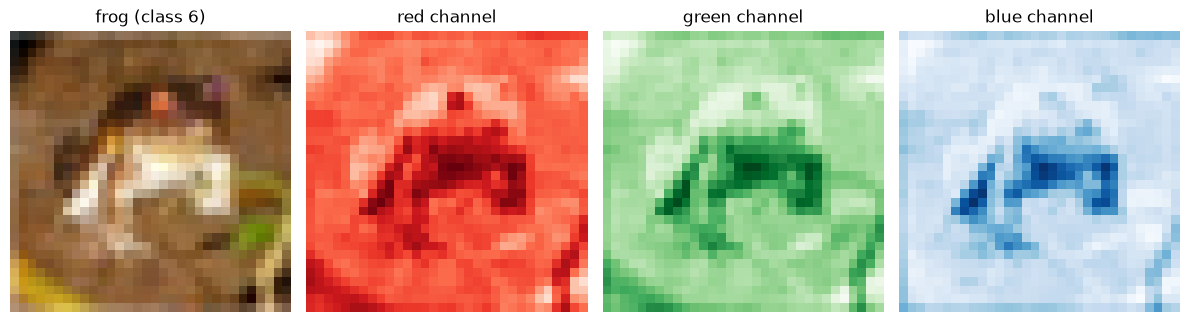

In [59]:
image_tensor, label_index = cifar_train_full[0]
class_name = cifar_train_full.classes[label_index]

mean = torch.tensor(cifar_mean).view(3, 1, 1)
std = torch.tensor(cifar_std).view(3, 1, 1)
display_image = (image_tensor * std + mean).clamp(0, 1)   # undo the normalization
display_image = display_image.permute(1, 2, 0)            # (3, 32, 32) -> (32, 32, 3)

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
axes[0].imshow(display_image)
axes[0].set_title(f"{class_name} (class {label_index})")
for ax, channel, name, colour_map in zip(
    axes[1:], range(3), ["red", "green", "blue"], ["Reds", "Greens", "Blues"]
):
    ax.imshow(display_image[:, :, channel], cmap=colour_map)
    ax.set_title(f"{name} channel")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### A slightly larger network

The architecture follows the same recipe, with two changes: the input has 3 channels instead of 1, and
there are two convolutions between each pooling step instead of one, so the network can build up more
complex patterns before losing resolution. Working out the shapes is exercise 2A, which you have already
done: `32 -> 16 -> 8`, so the flatten produces `128 * 8 * 8`.

In [60]:
class CIFAR10CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),    # 3 x 32 x 32 -> 32 x 32 x 32
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                               #             -> 32 x 16 x 16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                               #             -> 64 x 8 x 8
            nn.Conv2d(64, 128, kernel_size=3, padding=1),  #             -> 128 x 8 x 8
            nn.ReLU(),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                                  #             -> 8192
            nn.Linear(128 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 10),
        )

    def forward(self, images):
        return self.classifier(self.features(images))


model_cifar = CIFAR10CNN().to(device)
print(f"convolution part : {count_parameters(model_cifar.features):>9,}")
print(f"classifier part  : {count_parameters(model_cifar.classifier):>9,}")
print(f"total            : {count_parameters(model_cifar):>9,}")

convolution part :   139,424
classifier part  : 1,049,994
total            : 1,189,418


Five convolution layers instead of two, and still most of the parameters sit in the dense head, the same
pattern as with MNIST.

The next cell trains it. **This is the longest cell in the notebook**, typically 5 to 15 minutes on a CPU.

In [ ]:
loss_function_cifar = nn.CrossEntropyLoss()
optimizer_cifar = torch.optim.Adam(model_cifar.parameters(), lr=1e-3)
history_cifar = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}

epochs = 5
for epoch in range(epochs):
    train_loss, train_accuracy = train_one_epoch(
        model_cifar, cifar_train_loader, cifar_train, loss_function_cifar, optimizer_cifar
    )
    validation_loss, validation_accuracy = evaluate(
        model_cifar, cifar_validation_loader, cifar_validation, loss_function_cifar
    )
    history_cifar["loss"].append(train_loss)
    history_cifar["val_loss"].append(validation_loss)
    history_cifar["accuracy"].append(train_accuracy)
    history_cifar["val_accuracy"].append(validation_accuracy)
    print(
        f"epoch {epoch + 1}: "
        f"train accuracy={train_accuracy:.4f}  validation accuracy={validation_accuracy:.4f}"
    )

cifar_test_loss, cifar_test_accuracy = evaluate(model_cifar, cifar_test_loader, cifar_test, loss_function_cifar)
print(f"\nCIFAR-10 test accuracy: {cifar_test_accuracy:.4f}")

TypeError: train_one_epoch() takes 4 positional arguments but 5 were given

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_cifar["loss"], marker="o", label="train")
axes[0].plot(history_cifar["val_loss"], marker="o", label="validation")
axes[0].set(xlabel="epoch", ylabel="loss", title="CIFAR-10 loss")
axes[0].legend()
axes[1].plot(history_cifar["accuracy"], marker="o", label="train")
axes[1].plot(history_cifar["val_accuracy"], marker="o", label="validation")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="CIFAR-10 accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

Compare these curves with the MNIST ones. Here the two lines pull apart: the training accuracy keeps
climbing while the validation accuracy flattens, and the validation loss may even start rising. That is
overfitting, exactly as described in notebook 01 section 5, but now on images, where you can see it
happening within five epochs.

**Key terms.** *Normalization*: centring and scaling the input per channel. *Channel*: one colour layer
of an image. *RGB*: the red, green and blue channels together.

### Exercise: compare the two datasets

**A. Look and read off** (2 minutes). Put the two test accuracies next to each other. How much worse is
CIFAR-10, and does the gap surprise you given that both networks have the same kind of architecture?

**B. Do it yourself** (20 minutes). Build two variants of the CIFAR network and compare them fairly.
**Train on a subset so that one run takes about a minute**, otherwise you will only ever do this once:

```python
small_train = Subset(cifar_train, range(5000))
small_loader = DataLoader(small_train, batch_size=128, shuffle=True)
```

1. Write down your expectation before training.
2. Change one thing per variant: the number of convolution blocks, the number of filters, or the dropout
   rate. Keep the data, the split and the number of epochs fixed.
3. Record validation accuracy, validation loss, parameter count and training time for each.
4. Write a short conclusion: was the larger model worth its extra complexity?

**C. Going further** (optional). Take the best variant and train it on the full training set for more
epochs. Does the ranking from your subset experiment still hold? This is the question behind every
experiment run on a subset for speed.

In [ ]:
import time

# B. A starting point: training on a subset so that a run takes about a minute.
small_train = Subset(cifar_train, range(5000))
small_loader = DataLoader(small_train, batch_size=128, shuffle=True)

# started = time.time()
# variant = CIFAR10CNN().to(device)
# ...
# print(f"{time.time() - started:.0f} seconds, {count_parameters(variant):,} parameters")

<details>
<summary>Worked answer: Exercise</summary>

**A.** Roughly 99% against roughly 70%: about thirty points, with the same sort of network and the same
training budget. The difference is not the model but the problem. MNIST digits are centred, one colour
channel, always the same style of stroke. A CIFAR cat can be anywhere in the frame, in any pose, any
colour, against any background, and "cat" is a far vaguer visual concept than "the digit 7". More data
variation with the same amount of data means a harder problem.

**B.** What you usually find:

- **more filters or an extra block**: training accuracy rises, validation accuracy hardly moves. With
  5,000 images there is not enough data to support the extra capacity, so it goes into memorization.
- **more dropout**: a smaller gap between the curves, sometimes a slightly better validation score.
- **fewer parameters in the dense head** (for instance by adding a pooling layer before the flatten):
  often the best trade: much smaller, barely worse.

The conclusion is almost always the same on CIFAR-10 at this scale: architecture is not the bottleneck,
data is. That is precisely why notebook `09 Data Augmentation` and notebook `11 Transfer Learning` exist.

**C.** Often it does not hold entirely. A subset favours small models, because large ones need more data
to come into their own. A subset experiment is a way of narrowing the field quickly, not of picking the
final winner, and that caveat belongs in your conclusion whenever you use one.

</details>

## 10. Comparing the two datasets

| | MNIST | CIFAR-10 |
|---|---|---|
| Image | 28 x 28, 1 channel | 32 x 32, 3 channels |
| Classes | 10 digits | 10 object categories |
| Variation | small: centred, same style | large: pose, background, colour, lighting |
| Test accuracy after 5 epochs | around 99% | around 70% |
| Bottleneck | none worth mentioning | data variation, not architecture |

The same recipe, wildly different results. Two things follow from that.

First, **a benchmark score means nothing without its dataset**. "97% accuracy" is excellent on CIFAR-10
and mediocre on MNIST. Always report what you measured on.

Second, **the dataset decides what a good network looks like.** On MNIST almost any small CNN works, so
architecture choices barely matter. On CIFAR-10 they start to matter, and data quantity and augmentation
matter even more. If you want to push that 70% higher, the productive routes are not "more layers" but:
more data or augmentation (notebook `09`), better training and regularization (notebooks `07` and `08`),
or a network that has already learned from millions of images (notebook `11 Transfer Learning`). That
last one is usually by far the most effective, and it is where this series is heading.

## Typical mistakes

The CNN-specific errors that cost the most time, and how to recognize them.

| Mistake | What you see | What to do |
|---|---|---|
| The flatten size no longer matches after changing a layer | `RuntimeError: mat1 and mat2 shapes cannot be multiplied` | print the shape after every layer, as in section 6 |
| Channel order mixed up | `Invalid shape (3, 32, 32) for image data`, or a picture that looks like noise | PyTorch is `(C, H, W)`, Matplotlib wants `(H, W, C)`: use `.permute(1, 2, 0)` |
| Forgetting `model.eval()` | evaluation scores that are worse and vary between runs | dropout stays active; call `model.eval()` before evaluating |
| Displaying normalized images without undoing it | strange colours, warnings about clipping | multiply by `std`, add `mean`, then `.clamp(0, 1)` |
| Normalization statistics computed over all the data | test scores that are slightly too good | compute them on the training set only |
| Softmax at the end of the network *and* `CrossEntropyLoss` | the network learns slowly or not at all | `CrossEntropyLoss` applies softmax itself; end with raw logits |
| Choosing based on the test set | a model that disappoints in practice | choose on validation, touch the test set once |
| Concluding from one run | two variants that "differ" by half a percent | repeat with another seed and compare the spread |

## Glossary

| Term | In one line |
|---|---|
| Filter / kernel | the small grid of weights that slides across the image |
| Kernel size | how large that window is, usually 3 by 3 |
| Feature map | the output of one filter across the whole image |
| Channel | one layer of an image: 1 for grayscale, 3 for RGB |
| Padding | a border of zeros so the output keeps its size |
| Stride | how far the window jumps per step |
| Receptive field | how much of the original image one value has seen |
| Pooling | reducing resolution by summarizing blocks; max pooling keeps the largest |
| Flatten | laying all feature maps out in a single row of numbers |
| Convolution part / classifier | finding patterns versus turning them into class scores |
| Logits | raw scores before softmax, what `CrossEntropyLoss` expects |
| Normalization | centring and scaling the input per channel |
| `model.train()` / `model.eval()` | training mode versus evaluation mode, matters for dropout |
| `torch.no_grad()` | do not track gradients; for evaluation |
| Translation invariance | recognizing a pattern wherever it appears |

## Knowledge check

Answer these before opening the suggested answers.

1. Why does a convolution need far fewer parameters than a dense layer on the same image?
2. Where does the `7` in `64 * 7 * 7` come from?
3. What does `padding=1` do with `kernel_size=3`, and why is that combination so common?
4. What does max pooling throw away, and what do you get in return?
5. Why is there no softmax at the end of the network?
6. What goes wrong if you forget `model.eval()` before evaluating?
7. Why does the same kind of network score around 99% on MNIST and around 70% on CIFAR-10?
8. You add a convolution block and get a shape error. What is the fastest way to find out what is wrong?

<details>
<summary>Suggested answers</summary>

1. Because the filter is shared: the same small set of weights is applied at every position, instead of a
   separate weight per pixel position. 320 parameters against 25,120 in the comparison in section 2, and
   the shared version also finds its pattern anywhere in the image.
2. From the two pooling layers: 28 halves to 14, and 14 halves to 7. The convolutions keep the size
   because of `padding=1`, so pooling is the only thing that shrinks it.
3. They cancel out: the padding adds exactly as many pixels as the 3 by 3 window costs, so height and
   width stay the same. That makes a network easy to reason about: only the pooling layers change the
   size.
4. It throws away three quarters of the values, so the exact position of a response is lost. In return
   you get a cheaper network and a little tolerance for shifts.
5. Because `nn.CrossEntropyLoss` applies softmax internally. Doing it twice makes the gradients much
   smaller and training slower.
6. Dropout stays active during evaluation, so units are randomly switched off. Your scores come out worse
   and differ from run to run, on data that has not changed at all.
7. Not because of the network but because of the problem. CIFAR-10 images vary enormously in pose,
   background, colour and lighting, and "cat" is a much vaguer visual category than "the digit 7". The
   same amount of data has to cover far more variation.
8. Send one batch through the layers one at a time and print the shape after each, as in section 6. The
   step where the number stops being what you expected is the step that is wrong.

</details>

## Recap

- A convolution slides a small filter over the image and computes one number per position; the filter
  values determine which pattern it responds to.
- `kernel_size=3, padding=1` leaves the size unchanged; `MaxPool2d(2)` halves it. Those two rules give you
  every shape in the network, including the flatten size.
- Pooling trades resolution for cost and shift tolerance.
- Convolutions are cheap because they share weights; the dense layer after the flatten holds most of the
  parameters.
- A trained network learns edge detectors in its first layer without being told to.
- The same architecture gives very different results on different datasets. The score belongs to the
  dataset, not to the network.
- Read learning curves as training against validation (notebook 01 section 5): the gap between them is the
  overfitting signal.